<a href="https://colab.research.google.com/github/PalQuisp/Sis420-int/blob/main/lab07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio: K-Means, aprendizaje semisupervisado y aprendizaje activo

**Base de trabajo:** se conserva la lógica del material del docente: generar datos con `make_blobs`, variar aleatoriamente el número y la posición de los centros, controlar la dispersión con `cluster_std`, aplicar `KMeans` y visualizar los grupos.

> Ejecuta las celdas en orden. Los datos sintéticos de los puntos 1 y 2 tienen etiquetas de origen únicamente para poder comparar visualmente cómo se distribuyeron; K-Means no utiliza esas etiquetas durante el entrenamiento.

## Librerías

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from mpl_toolkits.mplot3d import Axes3D

SEED = 42
rng = np.random.default_rng(SEED)

# Punto 1. Dataset 2D y K-Means

Se genera aleatoriamente:
1. Entre **1 y 20 centroides**.
2. Posiciones de los centroides con una separación mínima aproximada.
3. Una dispersión distinta para cada centroide.
4. Un número distinto de puntos para cada centroide.

Para facilitar la comprobación visual, las posiciones se aceptan solamente cuando quedan suficientemente separadas. `make_blobs` crea los puntos alrededor de esas posiciones.

In [ ]:
def generar_centros_separados(n_centros, dimensiones=2, limites=(-30, 30),
                              distancia_minima=10, rng=None, max_intentos=10000):
    """Genera centros aleatorios procurando que estén separados."""
    if rng is None:
        rng = np.random.default_rng()
    centros = []
    intentos = 0
    while len(centros) < n_centros and intentos < max_intentos:
        candidato = rng.uniform(limites[0], limites[1], size=dimensiones)
        if not centros or min(np.linalg.norm(candidato - c) for c in centros) >= distancia_minima:
            centros.append(candidato)
        intentos += 1
    if len(centros) < n_centros:
        raise RuntimeError("No se pudieron ubicar los centros separados. Amplía los límites o reduce la distancia mínima.")
    return np.array(centros)

N = int(rng.integers(1, 21))  # 1 a 20, ambos incluidos
centros_reales_2d = generar_centros_separados(
    N, dimensiones=2, limites=(-30, 30), distancia_minima=10, rng=rng
)
dispersiones_2d = rng.uniform(0.4, 2.0, size=N)  # equivalente a blob_std
puntos_por_centro_2d = rng.integers(100, 501, size=N)  # 100 a 500 por grupo

# make_blobs acepta un total por grupo; se entrega un vector con la cantidad de cada centro.
X2, y2_origen = make_blobs(
    n_samples=puntos_por_centro_2d,
    centers=centros_reales_2d,
    cluster_std=dispersiones_2d,
    random_state=SEED
)

print("Número de centroides generados:", N)
print("\nCentros originales (x, y):\n", np.round(centros_reales_2d, 2))
print("\nDispersión por centroide:", np.round(dispersiones_2d, 2))
print("\nPuntos generados por centroide:", puntos_por_centro_2d)
print("Total de puntos:", len(X2))
print("Forma de X2:", X2.shape)

Número de centroides generados: 19

Centros originales (x, y):
 [[-20.86  11.78]
 [ -3.23  -7.14]
 [ -8.29 -24.74]
 [-22.92  27.71]
 [ 24.51  11.98]
 [-11.64   4.75]
 [  5.05   8.99]
 [-24.93  -5.05]
 [  5.45 -28.63]
 [ 27.51  -1.06]
 [ 16.96 -25.04]
 [ 19.58  23.77]
 [-10.97  27.17]
 [-20.12 -27.31]
 [ 14.81 -14.25]
 [ 26.21 -15.54]
 [  5.96  22.47]
 [-29.16 -16.22]
 [-15.8  -15.04]]

Dispersión por centroide: [1.31 1.07 0.48 1.   1.24 0.56 1.73 0.48 1.88 0.56 1.75 1.84 1.97 1.68
 1.65 1.43 1.65 0.62 1.26]

Puntos generados por centroide: [300 229 306 487 443 434 285 414 254 375 356 200 206 124 156 273 291 166
 267]
Total de puntos: 5566
Forma de X2: (5566, 2)


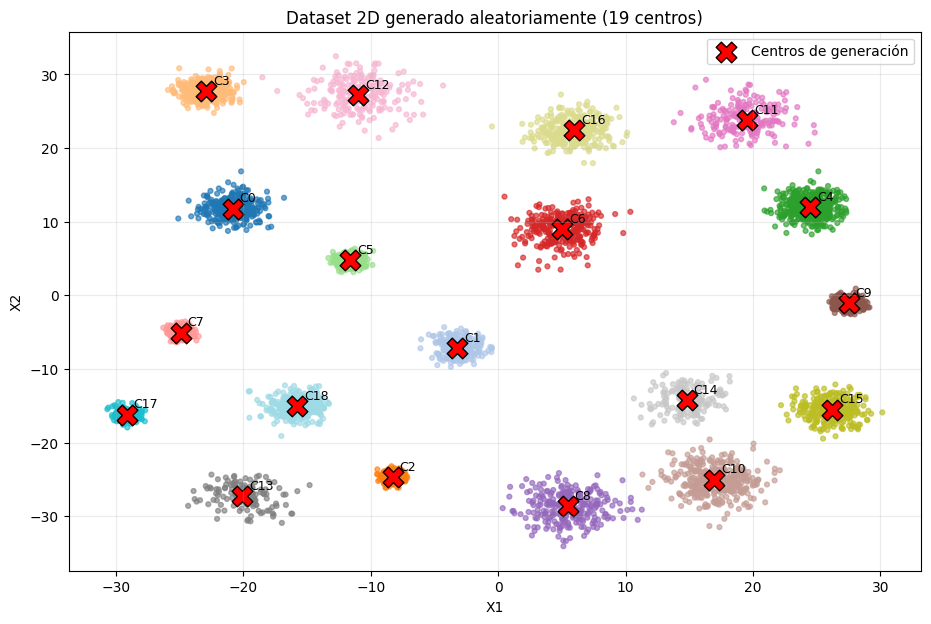

In [ ]:
plt.figure(figsize=(11, 7))
plt.scatter(X2[:, 0], X2[:, 1], s=12, alpha=0.65, c=y2_origen, cmap="tab20")
plt.scatter(centros_reales_2d[:, 0], centros_reales_2d[:, 1],
            marker="X", s=220, c="red", edgecolor="black", label="Centros de generación")
for i, (cx, cy) in enumerate(centros_reales_2d):
    plt.annotate(f"C{i}", (cx, cy), xytext=(5, 5), textcoords="offset points", fontsize=9)
plt.title(f"Dataset 2D generado aleatoriamente ({N} centros)")
plt.xlabel("X1"); plt.ylabel("X2"); plt.grid(alpha=0.25); plt.legend()
plt.show()

## Entrenar K-Means y comparar los centroides finales

Se usa el número de grupos generado (`k=N`). **K-Means no conoce los centros originales**: calcula sus propios centroides a partir de los puntos.

In [ ]:
kmeans2 = KMeans(n_clusters=N, init="k-means++", n_init=10, max_iter=300, random_state=SEED)
etiquetas2 = kmeans2.fit_predict(X2)
centros_finales_2d = kmeans2.cluster_centers_

conteos2 = np.bincount(etiquetas2, minlength=N)
tabla_centros2 = pd.DataFrame({
    "Cluster KMeans": np.arange(N),
    "Centro X1": centros_finales_2d[:, 0],
    "Centro X2": centros_finales_2d[:, 1],
    "Cantidad de puntos asignados": conteos2
}).round(3)
display(tabla_centros2)
print("Iteraciones hasta converger:", kmeans2.n_iter_)
print("ARI frente a la procedencia sintética (solo comprobación):",
      round(adjusted_rand_score(y2_origen, etiquetas2), 4))

,Cluster KMeans,Centro X1,Centro X2,Cantidad de puntos asignados
0,0,-24.953,-5.065,414
1,1,24.489,11.972,443
2,2,5.550,-28.795,254
3,3,-22.925,27.778,489
4,4,-8.260,-24.708,306
5,5,5.901,22.410,291
6,6,26.163,-15.561,273
7,7,-3.143,-7.020,229
8,8,-20.875,11.758,300
9,9,27.485,-1.080,375


Iteraciones hasta converger: 3
ARI frente a la procedencia sintética (solo comprobación): 0.9992


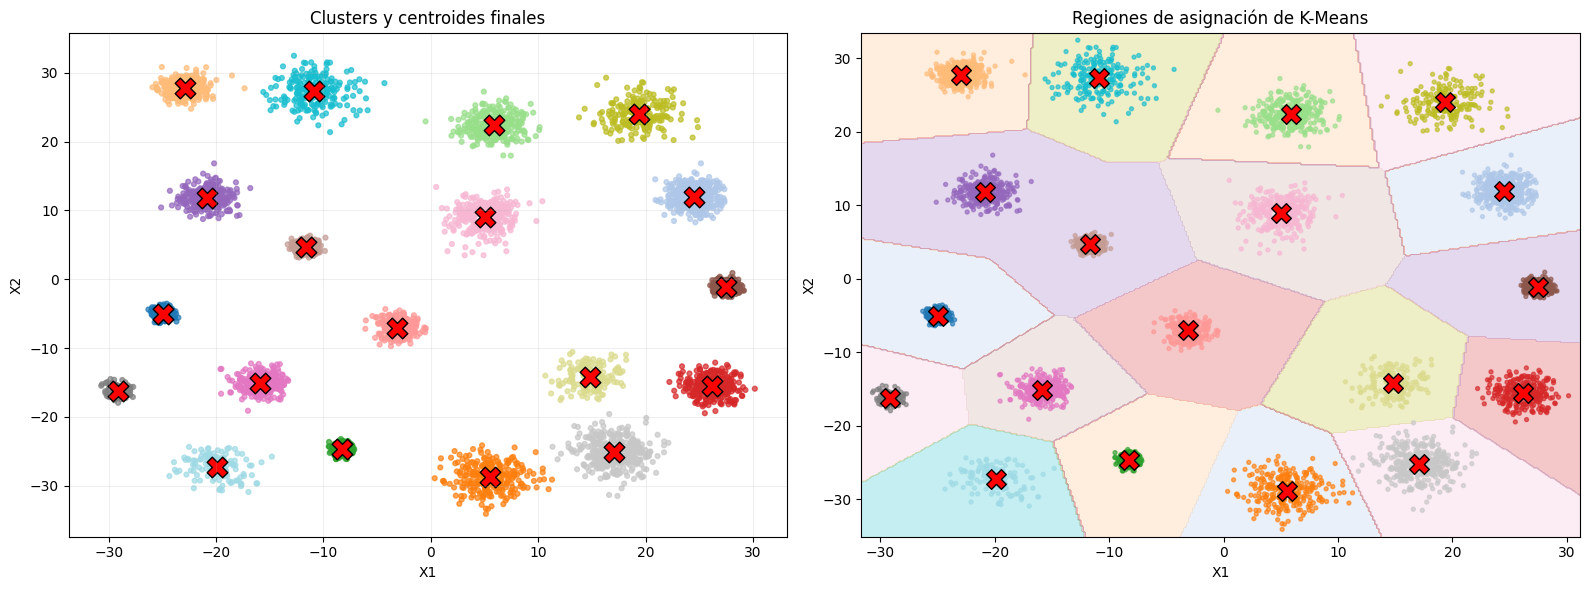

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].scatter(X2[:, 0], X2[:, 1], c=etiquetas2, cmap="tab20", s=12, alpha=0.7)
axes[0].scatter(centros_finales_2d[:, 0], centros_finales_2d[:, 1],
                marker="X", s=220, c="red", edgecolor="black")
axes[0].set_title("Clusters y centroides finales")
axes[0].set_xlabel("X1"); axes[0].set_ylabel("X2"); axes[0].grid(alpha=0.2)

# Visualización aproximada de fronteras: se predice el cluster para una malla 2D.
x_min, x_max = X2[:, 0].min()-1, X2[:, 0].max()+1
y_min, y_max = X2[:, 1].min()-1, X2[:, 1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 350), np.linspace(y_min, y_max, 350))
zz = kmeans2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[1].contourf(xx, yy, zz, alpha=0.25, cmap="tab20")
axes[1].scatter(X2[:, 0], X2[:, 1], c=etiquetas2, cmap="tab20", s=8, alpha=0.65)
axes[1].scatter(centros_finales_2d[:, 0], centros_finales_2d[:, 1],
                marker="X", s=200, c="red", edgecolor="black")
axes[1].set_title("Regiones de asignación de K-Means")
axes[1].set_xlabel("X1"); axes[1].set_ylabel("X2")
plt.tight_layout(); plt.show()

## Cinco puntos más cercanos a cada centroide final

In [ ]:
distancias2 = kmeans2.transform(X2)
filas_cercanas2 = []
for cluster_id in range(N):
    # Seleccionamos primero los puntos realmente asignados a este cluster.
    indices_cluster = np.where(etiquetas2 == cluster_id)[0]
    indices_ordenados = indices_cluster[np.argsort(distancias2[indices_cluster, cluster_id])]
    indices_top5 = indices_ordenados[:min(5, len(indices_ordenados))]
    for posicion, idx in enumerate(indices_top5, start=1):
        filas_cercanas2.append({
            "Cluster": cluster_id, "Posición": posicion, "Índice del punto": int(idx),
            "X1": X2[idx, 0], "X2": X2[idx, 1],
            "Distancia al centroide": distancias2[idx, cluster_id]
        })
tabla_cercanos2 = pd.DataFrame(filas_cercanas2).round(4)
display(tabla_cercanos2)

,Cluster,Posición,Índice del punto,X1,X2,Distancia al centroide
0,0,1,2079,-24.9778,-5.0438,0.0327
1,0,2,832,-24.9937,-5.0440,0.0460
2,0,3,89,-25.0033,-5.0308,0.0611
3,0,4,3076,-24.8933,-5.0338,0.0668
4,0,5,2779,-24.9557,-4.9964,0.0683
...,...,...,...,...,...,...
90,18,1,5102,-20.0085,-27.0927,0.1833
91,18,2,4679,-19.5969,-27.1947,0.3370
92,18,3,4267,-19.7554,-27.5862,0.3713
93,18,4,1483,-19.7749,-27.7081,0.4760


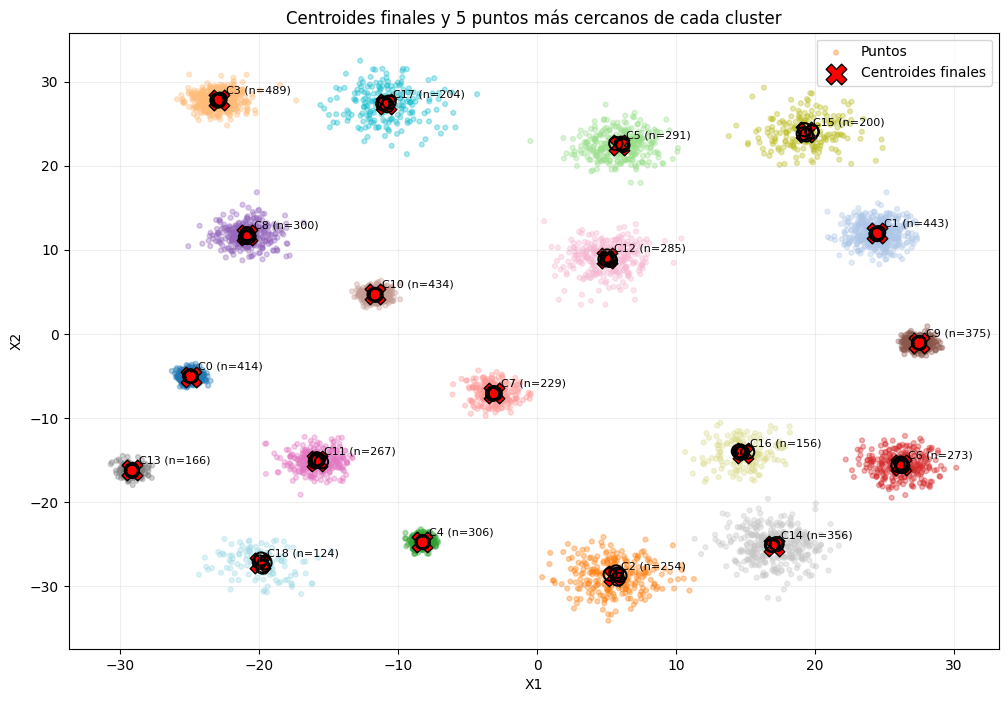

In [ ]:
plt.figure(figsize=(12, 8))
plt.scatter(X2[:, 0], X2[:, 1], c=etiquetas2, cmap="tab20", s=12, alpha=0.35, label="Puntos")
plt.scatter(centros_finales_2d[:, 0], centros_finales_2d[:, 1],
            marker="X", s=220, c="red", edgecolor="black", label="Centroides finales")
for cluster_id in range(N):
    sub = tabla_cercanos2[tabla_cercanos2["Cluster"] == cluster_id]
    if len(sub):
        plt.scatter(sub["X1"], sub["X2"], s=90, facecolors="none",
                    edgecolors="black", linewidths=1.5)
for i, (cx, cy) in enumerate(centros_finales_2d):
    plt.annotate(f"C{i} (n={conteos2[i]})", (cx, cy), xytext=(5, 5),
                 textcoords="offset points", fontsize=8)
plt.title("Centroides finales y 5 puntos más cercanos de cada cluster")
plt.xlabel("X1"); plt.ylabel("X2"); plt.grid(alpha=0.2); plt.legend()
plt.show()

## Graficar el proceso iterativo de K-Means

Para ilustrar las actualizaciones, ejecutamos K-Means con `max_iter=1` repetidamente. En cada paso se inicializa desde los centroides anteriores (`init=centros_iteracion`) y se observa cómo se mueven.

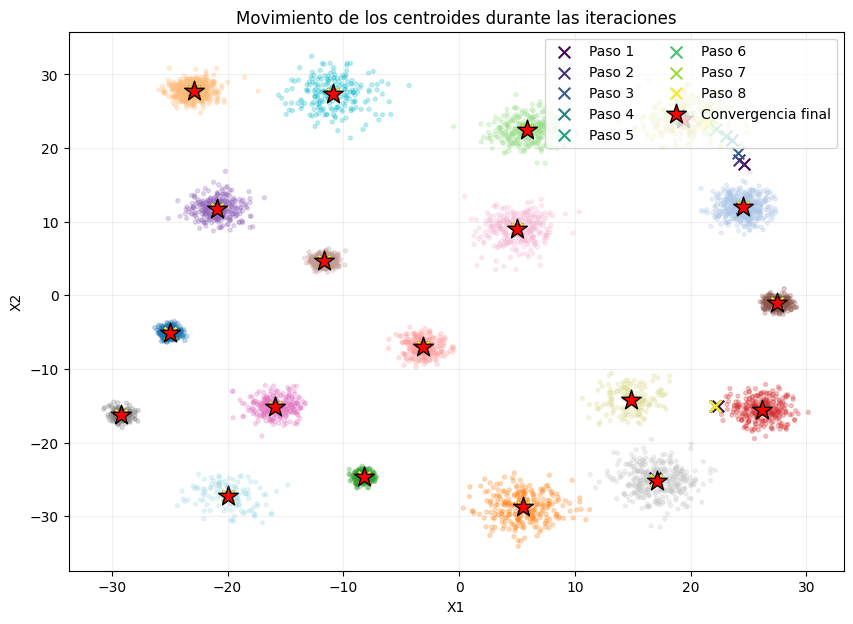

In [ ]:
centros_iteracion = None
historial_centros2 = []
for paso in range(1, min(8, 15) + 1):
    modelo_paso = KMeans(
        n_clusters=N, init="k-means++" if centros_iteracion is None else centros_iteracion,
        n_init=1, max_iter=1, algorithm="lloyd", random_state=SEED
    )
    modelo_paso.fit(X2)
    centros_iteracion = modelo_paso.cluster_centers_.copy()
    historial_centros2.append(centros_iteracion)

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(X2[:, 0], X2[:, 1], c=etiquetas2, cmap="tab20", s=8, alpha=0.25)
colores = plt.cm.viridis(np.linspace(0, 1, len(historial_centros2)))
for paso, (centros_paso, color) in enumerate(zip(historial_centros2, colores), start=1):
    ax.scatter(centros_paso[:, 0], centros_paso[:, 1], marker="x", s=70,
               color=color, label=f"Paso {paso}")
ax.scatter(centros_finales_2d[:, 0], centros_finales_2d[:, 1],
           marker="*", s=220, c="red", edgecolor="black", label="Convergencia final")
ax.set_title("Movimiento de los centroides durante las iteraciones")
ax.set_xlabel("X1"); ax.set_ylabel("X2"); ax.grid(alpha=0.2); ax.legend(ncol=2)
plt.show()

# Punto 2. Dataset 3D y K-Means

Se repite el procedimiento anterior, ahora con tres características (`X1`, `X2`, `X3`). La separación mínima se calcula con distancia euclidiana en 3D.

In [ ]:
N3 = int(rng.integers(1, 21))
centros_reales_3d = generar_centros_separados(
    N3, dimensiones=3, limites=(-35, 35), distancia_minima=14, rng=rng
)
dispersiones_3d = rng.uniform(0.5, 2.5, size=N3)
puntos_por_centro_3d = rng.integers(100, 401, size=N3)

X3, y3_origen = make_blobs(
    n_samples=puntos_por_centro_3d,
    centers=centros_reales_3d,
    cluster_std=dispersiones_3d,
    random_state=SEED + 1
)
print("Número de centros 3D:", N3)
print("Centros originales (X1, X2, X3):\n", np.round(centros_reales_3d, 2))
print("Dispersión por centro:", np.round(dispersiones_3d, 2))
print("Puntos por centro:", puntos_por_centro_3d)
print("Total:", len(X3), "| Forma:", X3.shape)

Número de centros 3D: 7
Centros originales (X1, X2, X3):
 [[-24.66  30.53  -4.35]
 [ -8.17  16.08   3.71]
 [ 30.53  19.62  -1.44]
 [ -8.65  34.06  15.24]
 [ 31.58 -26.71  24.54]
 [  9.6  -26.47   6.18]
 [ 22.78 -14.32  -2.9 ]]
Dispersión por centro: [1.38 1.1  2.34 2.06 0.72 2.49 2.26]
Puntos por centro: [147 306 185 334 351 113 132]
Total: 1568 | Forma: (1568, 3)


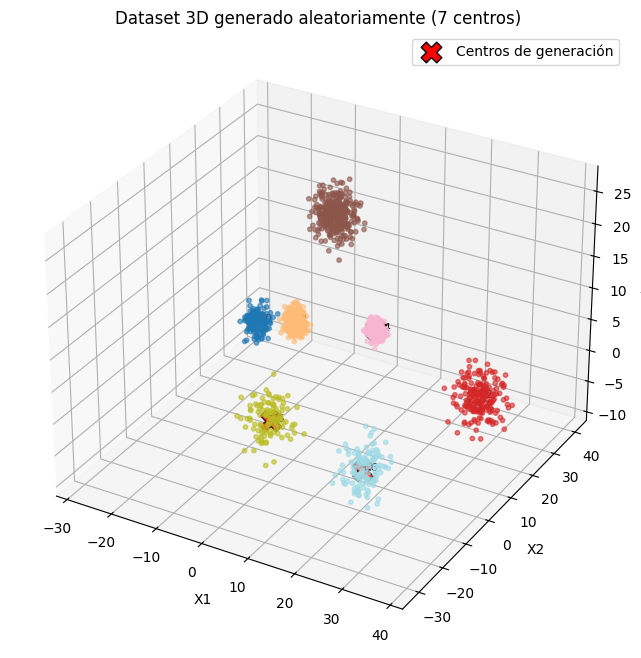

In [ ]:
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X3[:, 0], X3[:, 1], X3[:, 2], c=y3_origen, cmap="tab20", s=10, alpha=0.6)
ax.scatter(centros_reales_3d[:, 0], centros_reales_3d[:, 1], centros_reales_3d[:, 2],
           marker="X", s=220, c="red", edgecolor="black", label="Centros de generación")
for i, (cx, cy, cz) in enumerate(centros_reales_3d):
    ax.text(cx, cy, cz, f"C{i}", fontsize=8)
ax.set_title(f"Dataset 3D generado aleatoriamente ({N3} centros)")
ax.set_xlabel("X1"); ax.set_ylabel("X2"); ax.set_zlabel("X3"); ax.legend()
plt.show()

In [ ]:
kmeans3 = KMeans(n_clusters=N3, init="k-means++", n_init=10, max_iter=300, random_state=SEED)
etiquetas3 = kmeans3.fit_predict(X3)
centros_finales_3d = kmeans3.cluster_centers_
conteos3 = np.bincount(etiquetas3, minlength=N3)

tabla_centros3 = pd.DataFrame({
    "Cluster KMeans": np.arange(N3),
    "Centro X1": centros_finales_3d[:, 0],
    "Centro X2": centros_finales_3d[:, 1],
    "Centro X3": centros_finales_3d[:, 2],
    "Cantidad de puntos asignados": conteos3
}).round(3)
display(tabla_centros3)
print("Iteraciones:", kmeans3.n_iter_)
print("ARI frente a la procedencia sintética (solo comprobación):",
      round(adjusted_rand_score(y3_origen, etiquetas3), 4))

,Cluster KMeans,Centro X1,Centro X2,Centro X3,Cantidad de puntos asignados
0,0,22.825,-13.987,-2.677,132
1,1,-8.602,34.198,15.134,334
2,2,31.507,-26.667,24.533,351
3,3,30.834,19.733,-1.435,185
4,4,-8.125,16.109,3.697,306
5,5,-24.600,30.447,-4.323,147
6,6,9.261,-26.519,6.510,113


Iteraciones: 2
ARI frente a la procedencia sintética (solo comprobación): 1.0


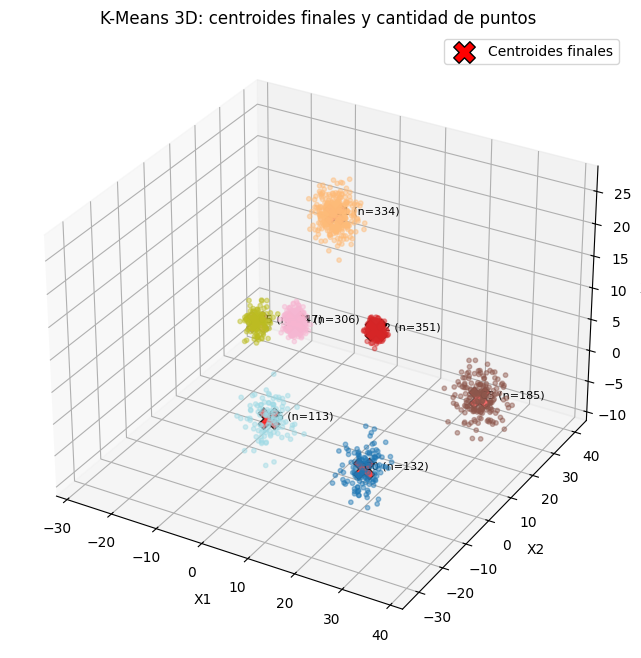

In [ ]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X3[:, 0], X3[:, 1], X3[:, 2], c=etiquetas3, cmap="tab20", s=10, alpha=0.45)
ax.scatter(centros_finales_3d[:, 0], centros_finales_3d[:, 1], centros_finales_3d[:, 2],
           marker="X", s=240, c="red", edgecolor="black", label="Centroides finales")
for i, (cx, cy, cz) in enumerate(centros_finales_3d):
    ax.text(cx, cy, cz, f"C{i} (n={conteos3[i]})", fontsize=8)
ax.set_title("K-Means 3D: centroides finales y cantidad de puntos")
ax.set_xlabel("X1"); ax.set_ylabel("X2"); ax.set_zlabel("X3"); ax.legend()
plt.show()

## Cinco puntos más cercanos a cada centroide en 3D

In [ ]:
distancias3 = kmeans3.transform(X3)
filas_cercanas3 = []
for cluster_id in range(N3):
    indices_cluster = np.where(etiquetas3 == cluster_id)[0]
    indices_ordenados = indices_cluster[np.argsort(distancias3[indices_cluster, cluster_id])]
    for posicion, idx in enumerate(indices_ordenados[:min(5, len(indices_ordenados))], start=1):
        filas_cercanas3.append({
            "Cluster": cluster_id, "Posición": posicion, "Índice del punto": int(idx),
            "X1": X3[idx, 0], "X2": X3[idx, 1], "X3": X3[idx, 2],
            "Distancia al centroide": distancias3[idx, cluster_id]
        })
tabla_cercanos3 = pd.DataFrame(filas_cercanas3).round(4)
display(tabla_cercanos3)

,Cluster,Posición,Índice del punto,X1,X2,X3,Distancia al centroide
0,0,1,1483,22.5737,-14.1602,-2.9411,0.4036
1,0,2,341,22.8467,-14.9192,-2.9424,0.9693
2,0,3,524,22.9760,-14.3655,-1.6626,1.0929
3,0,4,1324,22.5249,-13.7902,-3.7960,1.1754
4,0,5,1286,23.5613,-14.9807,-2.3038,1.2916
5,1,1,1153,-8.0669,34.4924,15.2931,0.6309
6,1,2,1244,-8.5446,33.5257,15.2220,0.6807
7,1,3,1037,-8.9219,34.8603,15.1219,0.7354
8,1,4,1371,-8.5064,34.2438,15.8681,0.7416
9,1,5,139,-8.6367,33.3952,15.1763,0.8049


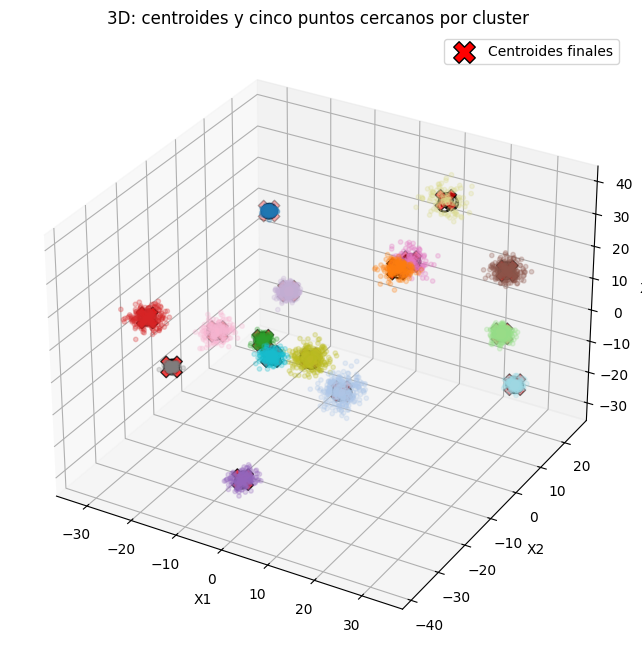

In [ ]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X3[:, 0], X3[:, 1], X3[:, 2], c=etiquetas3, cmap="tab20", s=10, alpha=0.25)
ax.scatter(centros_finales_3d[:, 0], centros_finales_3d[:, 1], centros_finales_3d[:, 2],
           marker="X", s=240, c="red", edgecolor="black", label="Centroides finales")
for cluster_id in range(N3):
    sub = tabla_cercanos3[tabla_cercanos3["Cluster"] == cluster_id]
    if len(sub):
        ax.scatter(sub["X1"], sub["X2"], sub["X3"], s=100, facecolors="none",
                   edgecolors="black", linewidths=1.5)
ax.set_title("3D: centroides y cinco puntos cercanos por cluster")
ax.set_xlabel("X1"); ax.set_ylabel("X2"); ax.set_zlabel("X3"); ax.legend()
plt.show()

# Punto 3. Dataset de imágenes sin etiquetas: aprendizaje semisupervisado y activo

## Dataset propuesto: STL-10 (partición `unlabeled`)

STL-10 es un dataset de imágenes a color de 96×96 píxeles. Su partición **`unlabeled` contiene 100.000 imágenes sin etiquetas**, y las imágenes tienen muchas más de 10 características si se representan como píxeles. Esto satisface el requisito de más de 10 características y más de 10.000 ejemplos.

- Página del dataset: https://cs.stanford.edu/~acoates/stl10/
- En este laboratorio se utiliza una muestra de la partición sin etiquetas para que el procesamiento sea más manejable.
- **Importante:** para aprendizaje semisupervisado se necesita una pequeña cantidad de ejemplos etiquetados. En el código se toman ejemplos de la partición `train` de STL-10 como conjunto etiquetado inicial y ejemplos de `unlabeled` como conjunto sin etiquetas. No se afirma que sean las mismas imágenes.
- Para aprendizaje activo, el modelo selecciona imágenes sobre las que tiene más incertidumbre. En una aplicación real, una persona revisa esas imágenes y asigna las etiquetas. La celda siguiente deja visible el proceso; para un trabajo formal, documenta las etiquetas que hayas asignado manualmente.

Instalación necesaria en Colab: `torch`, `torchvision`, `scikit-learn`, `matplotlib`. El primer uso descargará STL-10.

In [ ]:
# Si hace falta en Colab, descomenta:
# !pip -q install torch torchvision scikit-learn

import torch
from torch.utils.data import DataLoader
from torchvision.datasets import STL10
from torchvision import transforms
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

In [ ]:
# Descarga/carga del dataset. El primer uso puede tardar.
transformacion = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])
ruta_dataset = "./datos_stl10"

stl_etiquetado = STL10(root=ruta_dataset, split="train", download=True, transform=transformacion)
stl_sin_etiqueta = STL10(root=ruta_dataset, split="unlabeled", download=True, transform=transformacion)

n_etiquetado = len(stl_etiquetado)
n_sin_etiqueta = len(stl_sin_etiqueta)
print("Ejemplos etiquetados disponibles:", n_etiquetado)
print("Ejemplos sin etiqueta disponibles:", n_sin_etiqueta)
print("Tamaño original de imagen: 96 x 96 x 3")
print("Con redimensionamiento a 32x32 hay", 32*32*3, "valores de píxel por imagen.")

Ejemplos etiquetados disponibles: 5000
Ejemplos sin etiqueta disponibles: 100000
Tamaño original de imagen: 96 x 96 x 3
Con redimensionamiento a 32x32 hay 3072 valores de píxel por imagen.


## Preparar los datos

Para mantener un tiempo de ejecución razonable, se selecciona una muestra aleatoria de imágenes. Se reducen a 32×32 y se convierten en vectores de 3.072 valores. PCA comprime estos vectores a 100 componentes para acelerar el entrenamiento.

Las etiquetas de `train` se usan como pequeño conjunto etiquetado inicial; las de `unlabeled` no se usan porque no existen.

In [ ]:
rng_ml = np.random.default_rng(123)
N_LABELED = 1000
N_UNLABELED = 10000
N_TEST = 1000

idx_train = rng_ml.choice(len(stl_etiquetado), size=min(N_LABELED + N_TEST, len(stl_etiquetado)), replace=False)
idx_labeled = idx_train[:min(N_LABELED, len(idx_train)-1)]
idx_test = idx_train[min(N_LABELED, len(idx_train)-1):]

def imagenes_a_matriz(dataset, indices):
    xs, ys = [], []
    for idx in indices:
        img, label = dataset[int(idx)]
        xs.append(img.numpy().reshape(-1))
        ys.append(int(label))
    return np.asarray(xs, dtype=np.float32), np.asarray(ys, dtype=int)

X_labeled_raw, y_labeled = imagenes_a_matriz(stl_etiquetado, idx_labeled)
X_test_raw, y_test = imagenes_a_matriz(stl_etiquetado, idx_test)

idx_unlabeled = rng_ml.choice(len(stl_sin_etiqueta), size=min(N_UNLABELED, len(stl_sin_etiqueta)), replace=False)
X_unlabeled_raw = np.asarray([
    stl_sin_etiqueta[int(i)][0].numpy().reshape(-1) for i in idx_unlabeled
], dtype=np.float32)

print("X etiquetado:", X_labeled_raw.shape, "| y:", y_labeled.shape)
print("X sin etiquetas:", X_unlabeled_raw.shape)
print("X de prueba:", X_test_raw.shape, "| y:", y_test.shape)

X etiquetado: (1000, 3072) | y: (1000,)
X sin etiquetas: (10000, 3072)
X de prueba: (1000, 3072) | y: (1000,)


In [ ]:
# Estandarización y PCA: se ajustan únicamente con el conjunto etiquetado inicial.
scaler_img = StandardScaler()
X_labeled_scaled = scaler_img.fit_transform(X_labeled_raw)
X_unlabeled_scaled = scaler_img.transform(X_unlabeled_raw)
X_test_scaled = scaler_img.transform(X_test_raw)

pca = PCA(n_components=100, random_state=SEED)
X_labeled_pca = pca.fit_transform(X_labeled_scaled)
X_unlabeled_pca = pca.transform(X_unlabeled_scaled)
X_test_pca = pca.transform(X_test_scaled)
print("Varianza explicada por 100 componentes:", round(pca.explained_variance_ratio_.sum(), 4))

Varianza explicada por 100 componentes: 0.9045


## 3A. Aprendizaje semisupervisado mediante pseudoetiquetas

Procedimiento:
1. Entrenar un clasificador con el pequeño conjunto etiquetado.
2. Predecir las clases de las imágenes sin etiqueta.
3. Aceptar solamente pseudoetiquetas con confianza alta.
4. Reentrenar con los ejemplos etiquetados reales más las pseudoetiquetas seleccionadas.
5. Evaluar en el conjunto de prueba etiquetado, que no se utiliza para entrenar.

Las pseudoetiquetas son predicciones del modelo, no etiquetas reales. Pueden contener errores; por eso se usa un umbral de confianza.

In [ ]:
modelo_inicial = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
modelo_inicial.fit(X_labeled_pca, y_labeled)

prob_unlabeled = modelo_inicial.predict_proba(X_unlabeled_pca)
pseudo_y = modelo_inicial.classes_[np.argmax(prob_unlabeled, axis=1)]
confianza = np.max(prob_unlabeled, axis=1)

UMBRAL_CONFIANZA = 0.80
mask_pseudo = confianza >= UMBRAL_CONFIANZA
print("Pseudoetiquetas aceptadas:", int(mask_pseudo.sum()), "de", len(X_unlabeled_pca))
print("Proporción aceptada:", round(mask_pseudo.mean()*100, 2), "%")

if mask_pseudo.sum() > 0:
    X_semisup = np.vstack([X_labeled_pca, X_unlabeled_pca[mask_pseudo]])
    y_semisup = np.concatenate([y_labeled, pseudo_y[mask_pseudo]])
    modelo_semisup = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
    modelo_semisup.fit(X_semisup, y_semisup)
else:
    print("No hubo pseudoetiquetas por encima del umbral; se conserva el modelo inicial.")
    modelo_semisup = modelo_inicial

pred_test_inicial = modelo_inicial.predict(X_test_pca)
pred_test_semisup = modelo_semisup.predict(X_test_pca)
print("Accuracy modelo inicial:", round(accuracy_score(y_test, pred_test_inicial), 4))
print("Accuracy modelo semisupervisado:", round(accuracy_score(y_test, pred_test_semisup), 4))
print("\nReporte del modelo semisupervisado:")
print(classification_report(y_test, pred_test_semisup, zero_division=0))

Pseudoetiquetas aceptadas: 2008 de 10000
Proporción aceptada: 20.08 %
Accuracy modelo inicial: 0.299
Accuracy modelo semisupervisado: 0.286

Reporte del modelo semisupervisado:
              precision    recall  f1-score   support

           0       0.39      0.51      0.44        98
           1       0.16      0.14      0.15       105
           2       0.43      0.42      0.42        88
           3       0.14      0.13      0.14        97
           4       0.27      0.25      0.26       104
           5       0.12      0.13      0.13        99
           6       0.32      0.35      0.34        94
           7       0.17      0.18      0.17       102
           8       0.44      0.47      0.46       102
           9       0.41      0.30      0.34       111

    accuracy                           0.29      1000
   macro avg       0.29      0.29      0.29      1000
weighted avg       0.29      0.29      0.28      1000



## 3B. Aprendizaje activo: seleccionar ejemplos que más necesitan revisión

El aprendizaje activo busca reducir el esfuerzo de etiquetado. En lugar de escoger imágenes al azar, el modelo prioriza aquellas donde sus probabilidades son parecidas entre varias clases (menor confianza / mayor incertidumbre).

En esta celda se muestran ejemplos candidatos de la partición sin etiquetas. En una sesión real, la persona observa cada imagen y registra su clase. No se debe presentar la pseudoetiqueta como si fuera una etiqueta humana confirmada.

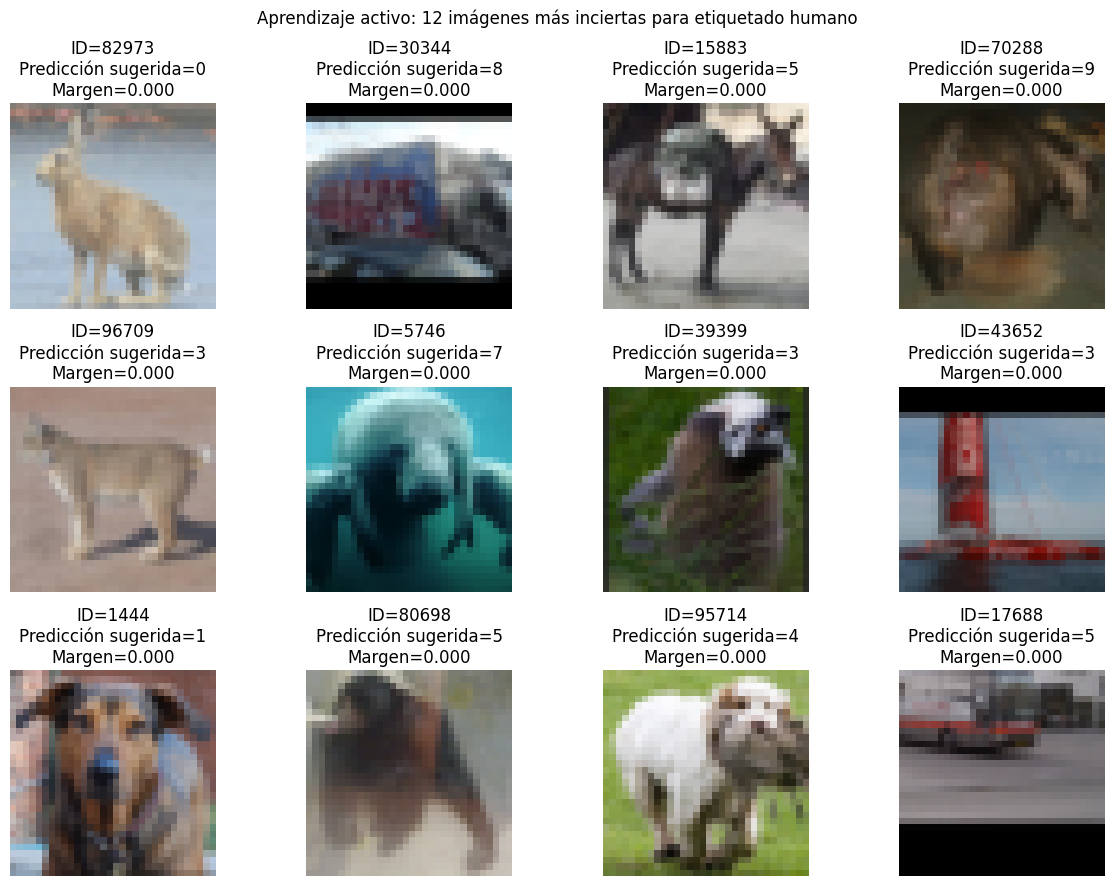

In [ ]:
# Incertidumbre por margen: diferencia entre las dos probabilidades más altas.
prob = modelo_inicial.predict_proba(X_unlabeled_pca)
prob_ordenadas = np.sort(prob, axis=1)
margen = prob_ordenadas[:, -1] - prob_ordenadas[:, -2]
indices_activos = np.argsort(margen)[:12]  # margen pequeño = mayor incertidumbre

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, idx_local in zip(axes.ravel(), indices_activos):
    idx_original = idx_unlabeled[idx_local]
    img, _ = stl_sin_etiqueta[int(idx_original)]
    ax.imshow(np.transpose(img.numpy(), (1, 2, 0)))
    clase_pred = int(modelo_inicial.predict(X_unlabeled_pca[idx_local:idx_local+1])[0])
    ax.set_title(f"ID={idx_original}\nPredicción sugerida={clase_pred}\nMargen={margen[idx_local]:.3f}")
    ax.axis("off")
plt.suptitle("Aprendizaje activo: 12 imágenes más inciertas para etiquetado humano")
plt.tight_layout()
plt.show()

### Registrar las etiquetas revisadas por una persona

Después de mirar las imágenes anteriores, el estudiante/docente debe escribir la clase real que identifica en cada imagen. Las clases numéricas de STL-10 son: 0 avión, 1 pájaro, 2 automóvil, 3 gato, 4 ciervo, 5 perro, 6 caballo, 7 mono, 8 barco, 9 camión.

No conviene automatizar estas etiquetas con la predicción del mismo modelo, porque eso no sería aprendizaje activo real: el objetivo es que un oráculo humano corrija o confirme ejemplos.

In [ ]:
# Completa manualmente las etiquetas para los IDs que revisaste.
# Formato: {posición_local_en_X_unlabeled: clase_real_0_a_9}
# Ejemplo de estructura (NO son etiquetas reales; reemplázalas tras inspeccionar las imágenes):
etiquetas_humanas = {
    # int(indices_activos[0]): 2,
    # int(indices_activos[1]): 0,
}

if etiquetas_humanas:
    ids_locales = np.array(list(etiquetas_humanas.keys()), dtype=int)
    y_humanas = np.array(list(etiquetas_humanas.values()), dtype=int)
    X_activo = X_unlabeled_pca[ids_locales]
    X_labeled_activo = np.vstack([X_labeled_pca, X_activo])
    y_labeled_activo = np.concatenate([y_labeled, y_humanas])
    modelo_activo = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
    modelo_activo.fit(X_labeled_activo, y_labeled_activo)
    pred_activo = modelo_activo.predict(X_test_pca)
    print("Cantidad de etiquetas humanas añadidas:", len(y_humanas))
    print("Accuracy tras aprendizaje activo:", round(accuracy_score(y_test, pred_activo), 4))
    print(classification_report(y_test, pred_activo, zero_division=0))
else:
    print("Aún no se ingresaron etiquetas humanas. Inspecciona las imágenes y completa etiquetas_humanas para ejecutar esta fase.")

Aún no se ingresaron etiquetas humanas. Inspecciona las imágenes y completa etiquetas_humanas para ejecutar esta fase.


## Conclusiones que debes reportar

1. **Puntos 1 y 2:** indicar el número aleatorio de centros, posiciones originales, dispersión, cantidad de puntos, centros finales de K-Means y cantidad de puntos por cluster.
2. **Cinco puntos cercanos:** la tabla lista los cinco puntos más cercanos *dentro del cluster asignado* a cada centroide, evitando mostrar puntos de otros grupos como vecinos del centroide.
3. **Proceso iterativo:** observar el movimiento de los centroides hasta que la asignación se estabiliza.
4. **Semisupervisado:** comparar el modelo entrenado solo con etiquetas reales frente al modelo que añade pseudoetiquetas de alta confianza. No asumir que añadir pseudoetiquetas siempre mejora el resultado.
5. **Activo:** explicar que se eligen muestras inciertas para que una persona las etiquete; después se incorporan al conjunto etiquetado y se vuelve a entrenar.
6. **Limitaciones:** STL-10 contiene imágenes naturales variadas. La representación por píxeles y PCA es una línea base sencilla, no necesariamente la mejor representación visual. Para una versión avanzada, se puede usar una red convolucional o embeddings de un modelo preentrenado.